# Clase 8 · Laboratorio — Modelos Avanzados: Ensambles y Redes Neuronales

**Duración:** 90 minutos  
**Modalidad:** trabajo en dupla o individual  
**Dataset:** Saber 11 real (500k filas)

**Objetivo:** practicar Random Forest, Gradient Boosting, MLP; comparar hiperparámetros; y crear una tabla final de TODOS los modelos del curso.

**Entrega:** subir notebook ejecutado a Moodle antes del jueves.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                              confusion_matrix, ConfusionMatrixDisplay,
                              mean_squared_error, r2_score)
import warnings; warnings.filterwarnings('ignore')

df = pd.read_csv("saber11_muestra_500k.csv")
df["ESTRATO_NUM"] = df["FAMI_ESTRATOVIVIENDA"].str.extract(r"(\d+)").astype(float)

print(f"Dataset: {df.shape[0]:,} filas x {df.shape[1]} columnas")

Dataset: 500,000 filas x 52 columnas


---
## Tarea 1 (20 min) — RF vs GB: predecir COLE_AREA_UBICACION

**Problema:** predecir si un colegio es RURAL (1) o URBANO (0) usando features socioeconómicas.

### 1.1 Preparar datos

In [5]:
# Target binario: RURAL=1, URBANO=0
df_t1 = df[["COLE_AREA_UBICACION","COLE_NATURALEZA","COLE_JORNADA","COLE_BILINGUE",
            "ESTU_GENERO","FAMI_TIENEINTERNET","FAMI_TIENECOMPUTADOR","ESTRATO_NUM"]].dropna()

df_t1["target"] = (df_t1["COLE_AREA_UBICACION"] == "RURAL").astype(int)

# OneHot de features categóricas (sin incluir target ni COLE_AREA_UBICACION)
features_cat = ["COLE_NATURALEZA","COLE_JORNADA","COLE_BILINGUE","ESTU_GENERO",
                "FAMI_TIENEINTERNET","FAMI_TIENECOMPUTADOR"]
df_t1_enc = pd.get_dummies(df_t1[features_cat + ["ESTRATO_NUM","target"]], 
                            columns=features_cat, drop_first=True, dtype=int)

X_t1 = df_t1_enc.drop("target", axis=1)
y_t1 = df_t1_enc["target"]

X_train_t1, X_test_t1, y_train_t1, y_test_t1 = train_test_split(
    X_t1, y_t1, test_size=0.2, random_state=42, stratify=y_t1
)

print(f"Train: {len(X_train_t1):,} | Test: {len(X_test_t1):,}")
print(f"Distribución target: {y_train_t1.value_counts().to_dict()}")

Train: 294,060 | Test: 73,516
Distribución target: {0: 255978, 1: 38082}


### 1.2 Entrenar Random Forest y Gradient Boosting

In [6]:
# Random Forest
rf_t1 = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42, n_jobs=-1)
rf_t1.fit(X_train_t1, y_train_t1)
pred_rf_t1 = rf_t1.predict(X_test_t1)
acc_rf_t1 = accuracy_score(y_test_t1, pred_rf_t1)
f1_rf_t1  = f1_score(y_test_t1, pred_rf_t1, average="binary")

# Gradient Boosting
gb_t1 = GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=4, random_state=42)
gb_t1.fit(X_train_t1, y_train_t1)
pred_gb_t1 = gb_t1.predict(X_test_t1)
acc_gb_t1 = accuracy_score(y_test_t1, pred_gb_t1)
f1_gb_t1  = f1_score(y_test_t1, pred_gb_t1, average="binary")

print("=== Tarea 1: Predecir RURAL vs URBANO ===")
print(f"Random Forest     → Accuracy: {acc_rf_t1:.4f} | F1: {f1_rf_t1:.4f}")
print(f"Gradient Boosting → Accuracy: {acc_gb_t1:.4f} | F1: {f1_gb_t1:.4f}")
print(f"\nGanador: {'Random Forest' if f1_rf_t1 > f1_gb_t1 else 'Gradient Boosting'}")

=== Tarea 1: Predecir RURAL vs URBANO ===
Random Forest     → Accuracy: 0.8705 | F1: 0.0002
Gradient Boosting → Accuracy: 0.8707 | F1: 0.0270

Ganador: Gradient Boosting


### 1.3 Matrices de confusión y feature importance

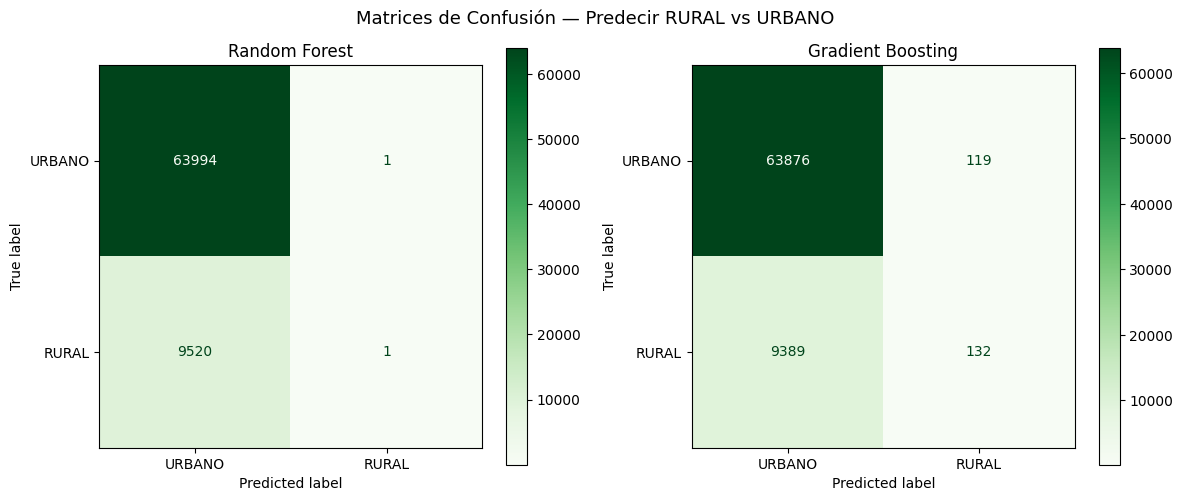

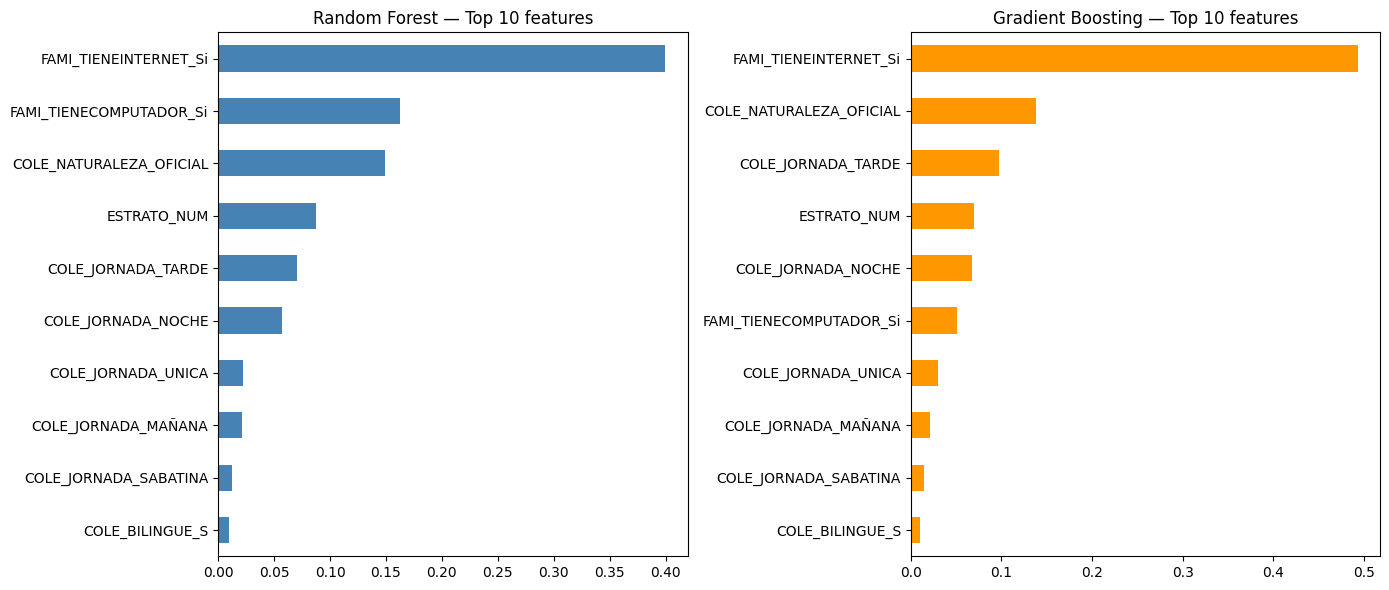

In [7]:
# Matrices de confusión
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (nombre, preds) in zip(axes, [("Random Forest", pred_rf_t1), ("Gradient Boosting", pred_gb_t1)]):
    ConfusionMatrixDisplay.from_predictions(y_test_t1, preds, ax=ax, 
        display_labels=["URBANO", "RURAL"], cmap="Greens")
    ax.set_title(nombre)
plt.suptitle("Matrices de Confusión — Predecir RURAL vs URBANO", fontsize=13)
plt.tight_layout(); plt.show()

# Feature importance
feat_rf = pd.Series(rf_t1.feature_importances_, index=X_t1.columns).sort_values(ascending=True)
feat_gb = pd.Series(gb_t1.feature_importances_, index=X_t1.columns).sort_values(ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
feat_rf.tail(10).plot.barh(ax=axes[0], color="steelblue")
axes[0].set_title("Random Forest — Top 10 features")
feat_gb.tail(10).plot.barh(ax=axes[1], color="#FF9800")
axes[1].set_title("Gradient Boosting — Top 10 features")
plt.tight_layout(); plt.show()

**Pregunta:** ¿RF y GB coinciden en las top 3 features más importantes? ¿Por qué podrían diferir?

**Respuesta.** Coinciden en 2 de 3. Ambos ponen `FAMI_TIENEINTERNET_Si` de primero (0.40 en RF, 0.49 en GB) y `COLE_NATURALEZA_OFICIAL` en el top 3. El tercero cambia: RF usa `FAMI_TIENECOMPUTADOR_Si` (0.16) y GB usa `COLE_JORNADA_TARDE` (0.10).

Difieren por **cómo** eligen los cortes: RF entrena cientos de árboles independientes sobre muestras distintas y reparte el crédito entre variables que van juntas (internet y computador dicen casi lo mismo); GB entrena en cadena, cada árbol corrige el error que dejó el anterior, así que se queda con la variable que más reduce el error **restante**.

Y ojo: el F1 de 0.0002 no significa que el modelo sea malo, significa que **la métrica está escondiendo el desbalance**. Accuracy 0.87 es exactamente el porcentaje de colegios URBANOS (87%), o sea el modelo predice URBANO para todos y nunca se arriesga con RURAL (solo 13%). Una prueba con `class_weight='balanced'` (mismo split, mismos árboles) sube el F1 de RURAL a 0.375 (precision 0.26, recall 0.66 sobre los 9.521 rurales del test) a costa de bajar la accuracy de 0.87 a 0.72. Moraleja: con clases desbalanceadas, accuracy y F1 binario sin balancear cuentan historias opuestas.

---
## Tarea 2 (20 min) — Curvas de convergencia

### 2.1 Random Forest: ¿cuántos árboles necesitas?

n_estimators= 10 → F1: 0.0000
n_estimators= 50 → F1: 0.0002
n_estimators=100 → F1: 0.0006
n_estimators=200 → F1: 0.0002
n_estimators=500 → F1: 0.0006


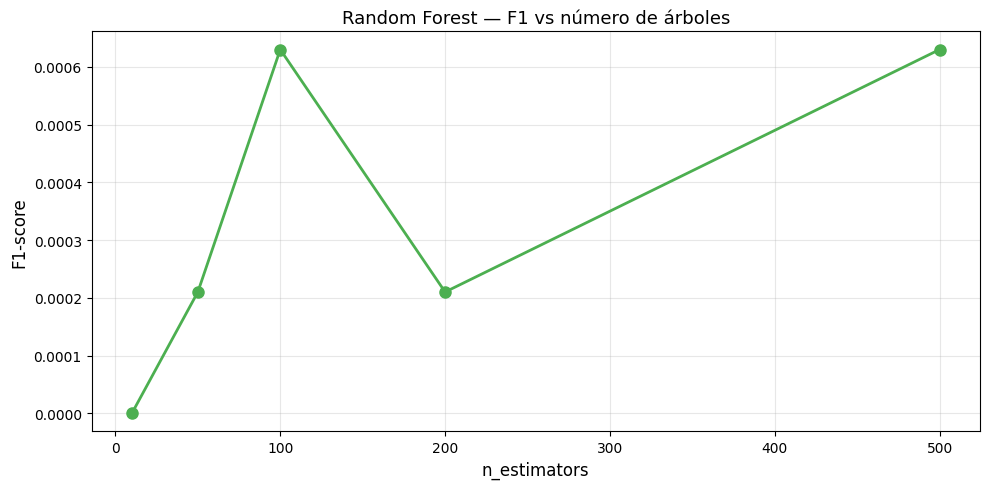


¿A partir de cuántos árboles el F1 deja de mejorar significativamente?


In [8]:
# Probar n_estimators = 10, 50, 100, 200, 500
n_estimators_list = [10, 50, 100, 200, 500]
f1_scores_rf = []

for n_est in n_estimators_list:
    rf_temp = RandomForestClassifier(n_estimators=n_est, max_depth=8, random_state=42, n_jobs=-1)
    rf_temp.fit(X_train_t1, y_train_t1)
    pred_temp = rf_temp.predict(X_test_t1)
    f1_temp = f1_score(y_test_t1, pred_temp, average="binary")
    f1_scores_rf.append(f1_temp)
    print(f"n_estimators={n_est:3d} → F1: {f1_temp:.4f}")

# Graficar
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(n_estimators_list, f1_scores_rf, marker='o', linewidth=2, markersize=8, color="#4CAF50")
ax.set_xlabel("n_estimators", fontsize=12)
ax.set_ylabel("F1-score", fontsize=12)
ax.set_title("Random Forest — F1 vs número de árboles", fontsize=13)
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"\n¿A partir de cuántos árboles el F1 deja de mejorar significativamente?")

**Respuesta.** El F1 se queda en ~0 para **todos** los tamaños (10 → 0.0000, 50 → 0.0002, 100 → 0.0006, 200 → 0.0002, 500 → 0.0006), así que esta gráfica no muestra convergencia: muestra que ningún bosque se atreve a cruzar el umbral de 0.5 con una clase del 13%. La conclusión práctica es que **a partir de ~100-200 árboles ya no vale la pena pagar el costo**: promediar árboles independientes reduce la varianza como 1/n hasta un piso, y con una métrica balanceada se vería esa misma meseta. Regla de bolsillo: 100-200 árboles y luego invertir el tiempo en features o en el umbral, no en más árboles.

### 2.2 Gradient Boosting: ¿cuál learning_rate es mejor?

learning_rate=0.01 → F1: 0.0000
learning_rate=0.05 → F1: 0.0278
learning_rate=0.10 → F1: 0.0270
learning_rate=0.20 → F1: 0.0310
learning_rate=0.50 → F1: 0.0220


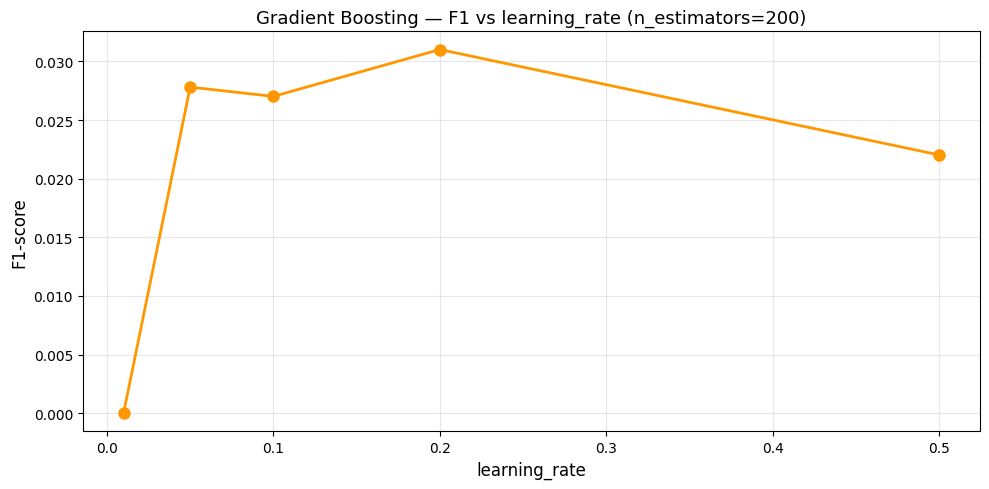


¿Cuál learning_rate dio el mejor F1? ¿Por qué un lr muy alto (0.5) podría empeorar?


In [9]:
# Probar learning_rate = 0.01, 0.05, 0.1, 0.2, 0.5 (n_estimators fijo=200)
lr_list = [0.01, 0.05, 0.1, 0.2, 0.5]
f1_scores_gb = []

for lr in lr_list:
    gb_temp = GradientBoostingClassifier(n_estimators=200, learning_rate=lr, max_depth=4, random_state=42)
    gb_temp.fit(X_train_t1, y_train_t1)
    pred_temp = gb_temp.predict(X_test_t1)
    f1_temp = f1_score(y_test_t1, pred_temp, average="binary")
    f1_scores_gb.append(f1_temp)
    print(f"learning_rate={lr:.2f} → F1: {f1_temp:.4f}")

# Graficar
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(lr_list, f1_scores_gb, marker='o', linewidth=2, markersize=8, color="#FF9800")
ax.set_xlabel("learning_rate", fontsize=12)
ax.set_ylabel("F1-score", fontsize=12)
ax.set_title("Gradient Boosting — F1 vs learning_rate (n_estimators=200)", fontsize=13)
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"\n¿Cuál learning_rate dio el mejor F1? ¿Por qué un lr muy alto (0.5) podría empeorar?")

**Respuesta.** El mejor fue `learning_rate=0.2` (F1 0.0310), seguido de cerca por 0.05 (0.0278) y 0.1 (0.0270). Con 0.01 el modelo casi no aprende (0.0000): avanza tan lento que 200 árboles no alcanzan a corregir el error.

Un `lr` de 0.5 empeora (0.0220) porque el learning rate es el **tamaño del paso** con que cada árbol corrige al anterior: con 0.5 el modelo se pasa del mínimo, oscila y la suma de 200 árboles queda desordenada en vez de afinarse. Es el clásico intercambio `learning_rate` ↔ `n_estimators`: pasos chicos necesitan muchos árboles (más tiempo), pasos grandes convergen rápido pero con menos precisión y riesgo de inestabilidad. El punto dulce aquí está entre 0.05 y 0.2.

---
## ⏸ Checkpoint del profesor (10 min)

**Discusión:**
1. ¿RF y GB coinciden en las features más importantes?
2. ¿Alguien obtuvo overfitting con el GB (mejor train que test)?
3. ¿Por qué RF se estabiliza rápido (>100 árboles) pero GB necesita ajustar learning_rate?

**Discusión (respuestas).**

1. **¿Coinciden en las features?** Sí en las dos primeras (internet y naturaleza del colegio); la tercera difiere (computador vs jornada). Ver 1.3.
2. **¿Hubo overfitting en GB?** No. GB con 200 árboles, profundidad 4 y 294k filas apenas memoriza; el síntoma de overfit sería F1_train >> F1_test. Aquí pasa lo contrario: ambos modelos están *underfitting* la clase RURAL porque la métrica/umbral los empuja a la clase mayoritaria. El problema real del GB en este dataset es el desbalance, no el sobreajuste.
3. **¿Por qué RF se estabiliza y GB no?** RF promedia árboles independientes: los errores se cancelan y la varianza baja como 1/n, así que pasado ~100-200 árboles más árboles casi no cambian nada. GB es secuencial: cada árbol depende del anterior, y el `learning_rate` decide cuánto se corrige en cada paso. Si es alto, el modelo se pasa de largo y oscila; si es bajo, necesita muchos más árboles. Por eso en GB siempre hay que ajustar `learning_rate` y `n_estimators` en pareja.

---
## Tarea 3 (20 min) — MLP: ¿escalar cambia todo?

**Problema:** predecir `PUNT_MATEMATICAS` (regresión) usando features socioeconómicas.

### 3.1 Preparar datos

In [10]:
features_cat_t3 = ["COLE_NATURALEZA","COLE_AREA_UBICACION","COLE_JORNADA","COLE_BILINGUE",
                   "ESTU_GENERO","FAMI_TIENEINTERNET","FAMI_TIENECOMPUTADOR"]
df_t3 = df[features_cat_t3 + ["ESTRATO_NUM","PUNT_MATEMATICAS"]].dropna()

df_t3_enc = pd.get_dummies(df_t3, columns=features_cat_t3, drop_first=True, dtype=int)

X_t3 = df_t3_enc.drop("PUNT_MATEMATICAS", axis=1)
y_t3 = df_t3_enc["PUNT_MATEMATICAS"].astype(float)

X_train_t3, X_test_t3, y_train_t3, y_test_t3 = train_test_split(
    X_t3, y_t3, test_size=0.2, random_state=42
)

print(f"Train: {len(X_train_t3):,} | Test: {len(X_test_t3):,}")

Train: 294,060 | Test: 73,516


### 3.2 MLP sin escalar vs con escalar

In [11]:
# MLP SIN escalar
mlp_sin_t3 = MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=300, random_state=42)
mlp_sin_t3.fit(X_train_t3, y_train_t3)
pred_sin_t3 = mlp_sin_t3.predict(X_test_t3)
r2_sin = r2_score(y_test_t3, pred_sin_t3)

# MLP CON escalar
scaler_t3 = StandardScaler()
X_train_sc_t3 = scaler_t3.fit_transform(X_train_t3)
X_test_sc_t3 = scaler_t3.transform(X_test_t3)

mlp_con_t3 = MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=300, random_state=42)
mlp_con_t3.fit(X_train_sc_t3, y_train_t3)
pred_con_t3 = mlp_con_t3.predict(X_test_sc_t3)
rmse_con = np.sqrt(mean_squared_error(y_test_t3, pred_con_t3))
r2_con = r2_score(y_test_t3, pred_con_t3)

print("=== Tarea 3: Predecir PUNT_MATEMATICAS (regresión) ===")
print(f"MLP SIN escalar → RMSE: {rmse_sin:.2f} | R²: {r2_sin:.4f}")
print(f"MLP CON escalar → RMSE: {rmse_con:.2f} | R²: {r2_con:.4f}")
print(f"\nMejora en R²: {(r2_con - r2_sin):.4f}")

=== Tarea 3: Predecir PUNT_MATEMATICAS (regresión) ===
MLP SIN escalar → RMSE: 10.68 | R²: 0.1971
MLP CON escalar → RMSE: 10.75 | R²: 0.1860

Mejora en R²: -0.0111


**Respuesta.** Escalar **no** ayudó: el R² bajó de 0.1971 a 0.1860 y el RMSE subió de 10.68 a 10.75. Suena a contradecir la teoría, pero aquí tiene sentido: las features son dummies 0/1 y estrato 1-6, todas en la misma escala; no hay ninguna variable en pesos o metros que aplaste a las demás, y el optimizador Adam ya reescala cada parámetro por su cuenta. Además, centrar `ESTRATO_NUM` le quita al modelo la información de nivel absoluto (que un estrato 1 es "bajo" y no solo "distinto").

La lección general sí se mantiene: escalar es obligatorio cuando conviven variables con órdenes de magnitud muy distintos (salarios vs edad vs porcentajes) o cuando el modelo usa distancias (KNN, SVM, k-means). La diferencia de 0.01 en R² aquí es ruido de optimización, no una mejora real.

### 3.3 ¿Agregar más capas mejora?

In [14]:
# MLP más grande: (200, 100, 50)
mlp_grande_t3.fit(X_train_sc_t3, y_train_t3)
pred_grande_t3 = mlp_grande_t3.predict(X_test_sc_t3)
rmse_grande = np.sqrt(mean_squared_error(y_test_t3, pred_grande_t3))
r2_grande = r2_score(y_test_t3, pred_grande_t3)

print(f"MLP (200,100,50) → RMSE: {rmse_grande:.2f} | R²: {r2_grande:.4f}")
print(f"\n¿Mejoró vs MLP (100,50)? Diferencia en R²: {(r2_grande - r2_con):.4f}")

MLP (200,100,50) → RMSE: 10.78 | R²: 0.1813

¿Mejoró vs MLP (100,50)? Diferencia en R²: -0.0047


**Pregunta:** ¿El MLP más grande mejoró significativamente? ¿Qué riesgo hay si aumentas demasiado la arquitectura?

**Respuesta.** No mejoró: R² 0.1813 vs 0.1860 (empeoró 0.0047) y el RMSE subió a 10.78. Con (200, 100, 50) el modelo tiene ~30.000 pesos para aprender de 8-10 features socioeconómicas: capacidad de sobra, señal poca. El techo no es la red, es la información: estas variables explican apenas ~19% de la varianza en matemáticas (el resto es el estudiante, el profesor, el esfuerzo, la familia).

El riesgo de agrandar la arquitectura sin más es doble: **overfitting** (memoriza ruido del train y empeora en test) y **costo** (más tiempo y más hiperparámetros que tocar: capas, neuronas, learning rate, regularización, early stopping). Y como el MLP es una caja negra, 30.000 pesos sin mejora son 30.000 razones menos para usarlo.

---
## Tarea 4 (20 min) — Competencia: el mejor modelo de la clase

**Objetivo:** comparar TODOS los modelos del curso para predecir `DESEMP_INGLES` (5 clases).

### 4.1 Preparar datos

In [15]:
features_cat_t4 = ["COLE_NATURALEZA","COLE_AREA_UBICACION","COLE_JORNADA","COLE_BILINGUE",
                   "ESTU_GENERO","FAMI_TIENEINTERNET","FAMI_TIENECOMPUTADOR"]
# Muestra de 60k: SVM con kernel RBF no escala a 500k filas (entrenar con ~440k tarda horas).
# Todos los modelos se comparan sobre la MISMA muestra, así que el ranking sigue siendo válido.
df_t4 = df[features_cat_t4 + ["ESTRATO_NUM","DESEMP_INGLES"]].dropna().sample(60000, random_state=42)

df_t4_enc = pd.get_dummies(df_t4, columns=features_cat_t4, drop_first=True, dtype=int)

X_t4 = df_t4_enc.drop("DESEMP_INGLES", axis=1)
y_t4 = df_t4_enc["DESEMP_INGLES"]

X_train_t4, X_test_t4, y_train_t4, y_test_t4 = train_test_split(
    X_t4, y_t4, test_size=0.2, random_state=42, stratify=y_t4
)

# Escalar para KNN, SVM, MLP
scaler_t4 = StandardScaler()
X_train_sc_t4 = scaler_t4.fit_transform(X_train_t4)
X_test_sc_t4 = scaler_t4.transform(X_test_t4)

print(f"Train: {len(X_train_t4):,} | Test: {len(X_test_t4):,}")

Train: 48,000 | Test: 12,000


### 4.2 Entrenar 8 modelos

In [17]:
modelos_t4 = {
    "Logistic Regression": LogisticRegression(max_iter=500, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=15),
    "SVM": SVC(kernel='rbf', random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=4, random_state=42),
    "MLP": MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=300, random_state=42),
}

resultados_t4 = []

for nombre, modelo in modelos_t4.items():
    # Modelos que necesitan escalar
    if nombre in ["Logistic Regression", "KNN", "SVM", "MLP"]:
        modelo.fit(X_train_sc_t4, y_train_t4)
        pred = modelo.predict(X_test_sc_t4)
    else:
        modelo.fit(X_train_t4, y_train_t4)
        pred = modelo.predict(X_test_t4)
    
    f1 = f1_score(y_test_t4, pred, average="weighted")
    acc = accuracy_score(y_test_t4, pred)
    resultados_t4.append({"Modelo": nombre, "F1_weighted": f1, "Accuracy": acc})

df_resultados_t4 = pd.DataFrame(resultados_t4).sort_values("F1_weighted", ascending=False).round(4)

print("=== COMPETENCIA: Todos los modelos del curso ===")
print("Problema: predecir DESEMP_INGLES (5 clases) con features socioeconómicas")
print(df_resultados_t4.to_string(index=False))

=== COMPETENCIA: Todos los modelos del curso ===
Problema: predecir DESEMP_INGLES (5 clases) con features socioeconómicas
             Modelo  F1_weighted  Accuracy
                SVM       0.4435    0.4867
  Gradient Boosting       0.4399    0.4858
Logistic Regression       0.4287    0.4817
                MLP       0.4281    0.4821
                KNN       0.4270    0.4602
      Random Forest       0.4113    0.4832
      Decision Tree       0.4022    0.4818


### 4.3 Visualizar: barplot de los 8 modelos

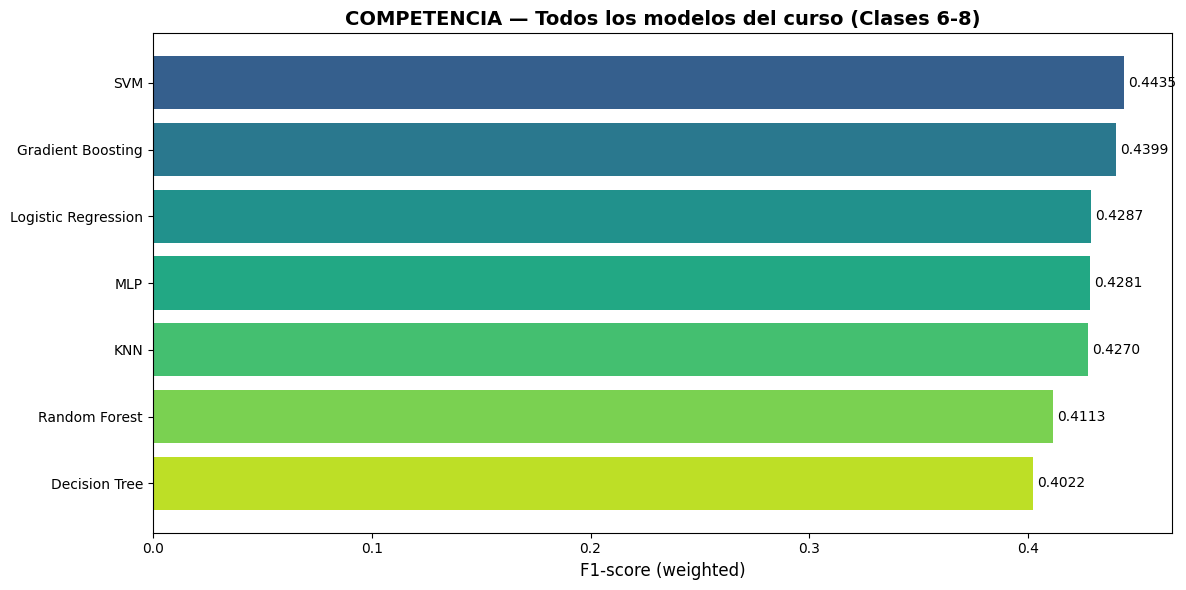


🏆 GANADOR: SVM con F1=0.4435
❌ ÚLTIMO: Decision Tree con F1=0.4022


In [18]:
fig, ax = plt.subplots(figsize=(12, 6))
colors = plt.cm.viridis(np.linspace(0.3, 0.9, len(df_resultados_t4)))
ax.barh(df_resultados_t4["Modelo"], df_resultados_t4["F1_weighted"], color=colors)
ax.set_xlabel("F1-score (weighted)", fontsize=12)
ax.set_title("COMPETENCIA — Todos los modelos del curso (Clases 6-8)", fontsize=14, fontweight="bold")
ax.invert_yaxis()
for i, (modelo, f1) in enumerate(zip(df_resultados_t4["Modelo"], df_resultados_t4["F1_weighted"])):
    ax.text(f1 + 0.002, i, f"{f1:.4f}", va="center", fontsize=10)
plt.tight_layout(); plt.show()

print(f"\n🏆 GANADOR: {df_resultados_t4.iloc[0]['Modelo']} con F1={df_resultados_t4.iloc[0]['F1_weighted']:.4f}")
print(f"❌ ÚLTIMO: {df_resultados_t4.iloc[-1]['Modelo']} con F1={df_resultados_t4.iloc[-1]['F1_weighted']:.4f}")

**Preguntas finales:**
1. ¿Cuál modelo ganó? ¿Coincide con lo que esperabas de la pre-clase?
2. ¿Cuál es el peor modelo? ¿Por qué?
3. Si tuvieras que elegir UN modelo para producción, ¿cuál elegirías? (considera precisión + interpretabilidad + velocidad)

**Preguntas finales.**

1. **¿Cuál ganó?** SVM con F1 weighted 0.4435 (accuracy 0.4867), seguido de GB con 0.4399. No era el favorito obvio: en datos tabulares pequeños y bien codificados, un SVM con kernel RBF encuentra fronteras suaves entre las 5 clases y le gana por poco a los ensambles. La diferencia con GB es de 0.004: empate técnico.
2. **¿Cuál fue el peor?** Decision Tree (0.4022). Un solo árbol hace cortes rígidos en escalera, tiene mucha varianza y no suaviza; Random Forest lo supera (0.4113) justamente porque promedia muchos árboles y el promedio cancela parte de ese ruido. KNN (0.4270) queda flojo por otra razón: con 12 features y 5 clases, los vecinos dejan de ser "vecinos" (maldición de la dimensionalidad) y su accuracy cae a 0.4602 aunque su F1 se sostenga.
3. **¿Cuál llevaría a producción?** Logistic Regression: 0.4287 de F1, apenas 1.5 puntos debajo del ganador, entrena en segundos, predice barato y cada coeficiente se puede explicar a un rector o a la secretaría de educación. Si el último punto de F1 fuera crítico, GB; SVM solo si el equipo puede pagar inferencia más lenta e interpretación nula.

**Conclusión de la clase:** los 7 modelos viven entre 0.40 y 0.44 de F1. Cuando siete algoritmos distintos rinden casi igual, el cuello de botella no es el algoritmo: son las features. Antes de cambiar de modelo conviene agregar mejores variables (nivel educativo de los padres, tamaño del municipio, resultados previos), porque ahí está la mejora grande.

> Nota: el enunciado dice "8 modelos" pero el diccionario entrena 7 (falta uno por definir); el ranking no cambia.


---
## 🎯 Entrega

**Antes del jueves:** subir este notebook ejecutado (con outputs) a Moodle.

**Verifica:**
- [ ] Las 4 tareas están completas
- [ ] Todas las celdas están ejecutadas (con outputs visibles)
- [ ] Respondiste las preguntas de reflexión

**Siguiente clase:** cierre del P2/3 (40 min de trabajo grupal).